# Xiao_Hongwei_HW6
Name: Hongwei Xiao  
GitHub username: Ga9a

## 1. Tree-based methods
### (a) APS data
I use the supplied training and test files. The positive class is an APS failure.
All 170 predictors are used for modeling; the feature ranking below is only for plotting.

In [1]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, accuracy_score, recall_score, precision_score)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from threadpoolctl import threadpool_limits

ROOT = Path('..') if Path('../data/aps_failure_training_set.csv').exists() else Path('.')
DATA, OUT = ROOT / 'data', ROOT / 'results'
OUT.mkdir(exist_ok=True)
SEED, JOBS = 42, 6
thread_limits = threadpool_limits(limits=JOBS)
pd.set_option('display.precision', 5)
sns.set_theme(style='whitegrid', context='notebook', font_scale=0.8)

def load_aps(filename):
    frame = pd.read_csv(DATA / filename, skiprows=20, na_values='na')
    return frame.drop(columns='class').astype('float32'), (frame['class'] == 'pos').astype(int)

X_train, y_train = load_aps('aps_failure_training_set.csv')
X_test, y_test = load_aps('aps_failure_test_set.csv')
assert X_train.shape == (60000, 170) and X_test.shape == (16000, 170)
assert list(X_train.columns) == list(X_test.columns)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Missing cells:', int(X_train.isna().sum().sum()), 'train;',
      int(X_test.isna().sum().sum()), 'test')

Train: (60000, 170) | Test: (16000, 170)
Missing cells: 850015 train; 228680 test


### (b)(i) Missing values
Common options are mean/median imputation, nearest-neighbor imputation, and
iterative imputation using the other predictors. Dropping incomplete rows can
discard too much data here. I use the training median because many features
are skewed and have large outliers. KNN and iterative imputation can use
relationships between features but require more computation.

The test data are transformed using training medians. In cross-validation,
medians are fitted separately on each training fold. The footnote in the
handout appears to reverse train and test; fitting preprocessing on the
training data follows the usual evaluation procedure.

In [2]:
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
Xtr = imputer.fit_transform(X_train).astype('float32')
Xte = imputer.transform(X_test).astype('float32')
assert np.isfinite(Xtr).all() and np.isfinite(Xte).all()
desc = pd.DataFrame(Xtr, columns=X_train.columns)
missing = X_train.isna().mean().sort_values(ascending=False)
missing.to_csv(OUT / 'missing_fraction.csv', header=['missing_fraction'])
display(missing.head(5).to_frame('train_missing_fraction'))
print('All-missing training features:', int(X_train.isna().all().sum()))

,train_missing_fraction
br_000,0.82107
bq_000,0.81203
bp_000,0.79567
bo_000,0.77222
ab_000,0.77215


All-missing training features: 0


### (b)(ii) Coefficient of variation
I calculate $CV=s/\bar x$ on the imputed training set, using sample standard
deviation ($ddof=1$). A feature with mean zero has an undefined CV and is
excluded from the ranking. The full table for all 170 features is saved in
`results/feature_cv.csv`; the 13 largest values are shown here.

In [3]:
variation = pd.DataFrame({'mean': desc.mean(), 'sample_sd': desc.std(ddof=1)})
variation['CV'] = variation.sample_sd / variation['mean'].replace(0, np.nan)
variation = variation.sort_values('CV', ascending=False)
variation.to_csv(OUT / 'feature_cv.csv', index_label='feature')
top = variation.CV.dropna().head(int(np.sqrt(170))).index.tolist()
assert len(top) == 13
table = variation.loc[top].copy()
table.insert(0, 'plot_label', [f'F{i+1}' for i in range(len(top))])
display(table)
print('Features:', len(variation), '| Undefined CV:', variation.CV.isna().sum())

,plot_label,mean,sample_sd,CV
cf_000,F1,143107.53125,3.50452e+07,244.88751
co_000,F2,143330.03125,3.50452e+07,244.50737
ad_000,F3,143438.29688,3.50452e+07,244.32281
cs_009,F4,770.50964,1.83328e+05,237.93057
dh_000,F5,4392.64062,5.41244e+05,123.21610
dj_000,F6,37.27133,4.37917e+03,117.49423
ag_000,F7,219.15773,2.03636e+04,92.91776
as_000,F8,125.40790,1.09522e+04,87.33250
ay_009,F9,1149.61963,9.74116e+04,84.73373
ak_000,F10,907.66071,7.29986e+04,80.42497


Features: 170 | Undefined CV: 0


### (b)(iii) Correlations
The matrix uses all 170 imputed training features. Feature positions follow
the CSV column order, also saved in `results/feature_order.csv`. Constant
features have undefined correlations and appear blank.

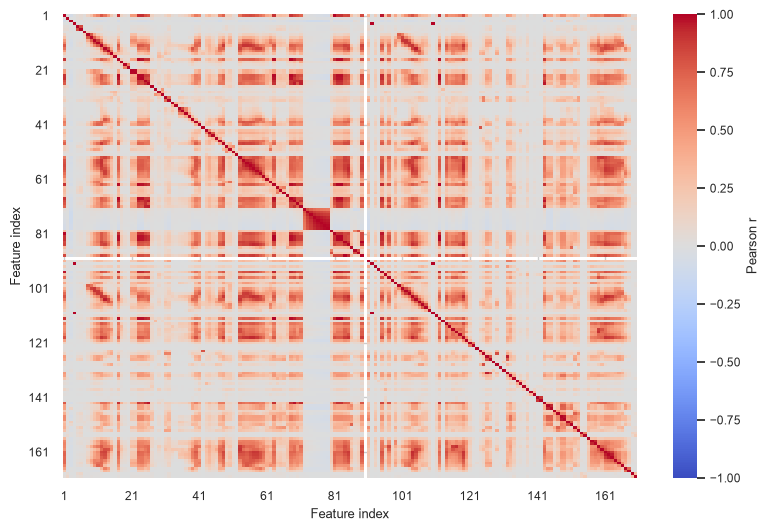

In [4]:
corr = desc.corr()
corr.to_csv(OUT / 'correlations.csv')
pd.DataFrame({'index': np.arange(1, 171), 'feature': desc.columns}).to_csv(
    OUT / 'feature_order.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 5.4))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, ax=ax,
            xticklabels=False, yticklabels=False, cbar_kws={'label': 'Pearson r'})
ticks = np.arange(0, 170, 20)
ax.set(xticks=ticks + 0.5, yticks=ticks + 0.5,
       xticklabels=ticks + 1, yticklabels=ticks + 1,
       xlabel='Feature index', ylabel='Feature index')
fig.tight_layout()
fig.savefig(OUT / 'correlation_matrix.png', dpi=170)
plt.show()

### (b)(iv) Scatter plots and box plots
The scatter matrix compares the 13 highest-CV predictors. To limit overplotting,
it uses a reproducible stratified sample of 3,000 training rows. This sampling
is only for the figure. The box plots and all fitted models use the full data.
F1-F13 refer to the feature names in the table above. Box plots are separated
by class and use a symmetric log scale to show the long tails while keeping zeros.

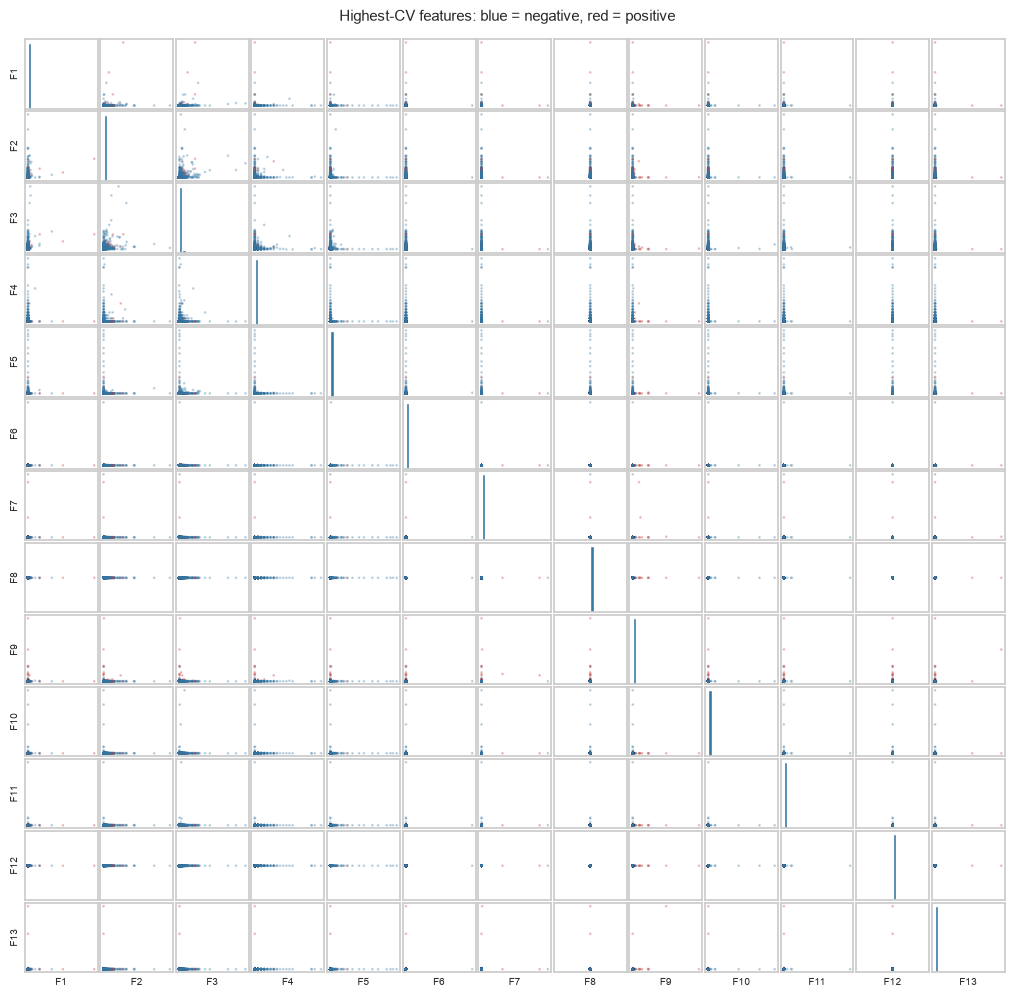

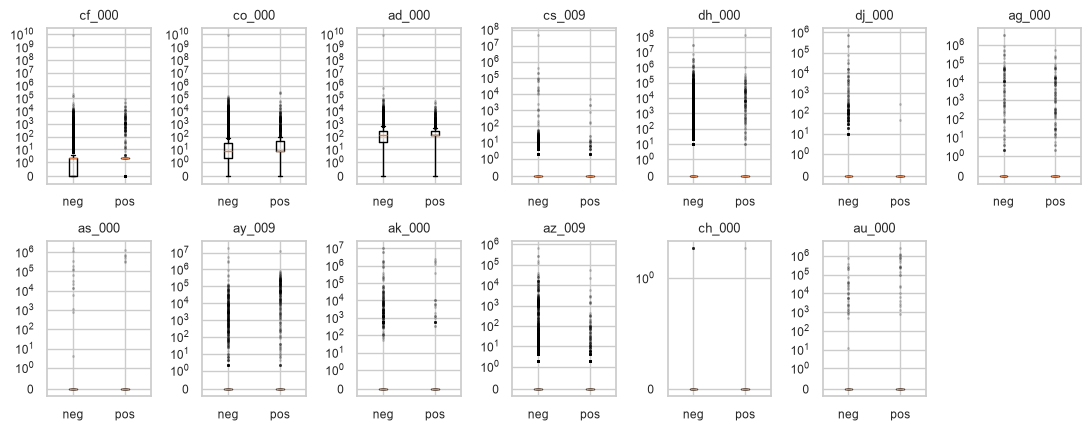

In [5]:
plot_idx, _ = train_test_split(np.arange(len(y_train)), train_size=3000,
    stratify=y_train, random_state=SEED)
z = desc.loc[plot_idx, top].to_numpy()
colors = np.where(y_train.iloc[plot_idx].to_numpy() == 1, '#c43c39', '#3478a5')
fig, axes = plt.subplots(13, 13, figsize=(10, 10))
for i in range(13):
    for j in range(13):
        ax = axes[i, j]
        if i == j:
            ax.hist(z[:, j], bins=20, color='#3478a5')
        else:
            ax.scatter(z[:, j], z[:, i], c=colors, s=1, alpha=0.25, rasterized=True)
        ax.set_xticks([]); ax.set_yticks([])
        if i == 12: ax.set_xlabel(f'F{j+1}', fontsize=7)
        if j == 0: ax.set_ylabel(f'F{i+1}', fontsize=7)
fig.suptitle('Highest-CV features: blue = negative, red = positive', fontsize=11)
fig.tight_layout(pad=0.2, rect=(0, 0, 1, 0.97))
fig.savefig(OUT / 'scatter_matrix.png', dpi=180)
plt.show()

fig, axes = plt.subplots(2, 7, figsize=(11, 4.4))
for name, ax in zip(top, axes.flat):
    ax.boxplot([desc.loc[y_train == c, name].to_numpy() for c in [0, 1]],
               tick_labels=['neg', 'pos'], showfliers=True,
               flierprops={'markersize': 1, 'alpha': 0.2})
    ax.set_yscale('symlog', linthresh=1)
    ax.set_title(name, fontsize=9)
axes.flat[-1].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / 'boxplots.png', dpi=170)
plt.show()

Many values are concentrated near zero with a few very large observations.
A large CV measures relative spread, not predictive usefulness. These plots
can suggest associations or class differences, but they do not establish
statistical significance or control for the other predictors.

### (b)(v) Class counts

In [6]:
counts = pd.DataFrame({'train': y_train.value_counts().sort_index(),
                       'test': y_test.value_counts().sort_index()})
counts.index = ['negative', 'positive']
display(counts)
display(Markdown(f'The training ratio is {counts.loc["negative", "train"] / counts.loc["positive", "train"]:.0f}:1. '
    f'Only {y_train.mean():.2%} of training observations are positive, so the data are strongly imbalanced. '
    f'Always predicting negative would have training error {y_train.mean():.2%} and test error {y_test.mean():.2%}, '
    'despite detecting no APS failures.'))

,train,test
negative,59000,15625
positive,1000,375


The training ratio is 59:1. Only 1.67% of training observations are positive, so the data are strongly imbalanced. Always predicting negative would have training error 1.67% and test error 2.34%, despite detecting no APS failures.

### (c) Random forest without class balancing
I use 200 trees, bootstrap sampling, and the square root of the number of
features at each split. Class weights are not used. All confusion matrices
have true classes on rows and predicted classes on columns, ordered neg/pos.
Predictions use a probability threshold of 0.5. Recall is included because
overall error alone can hide missed positive cases.

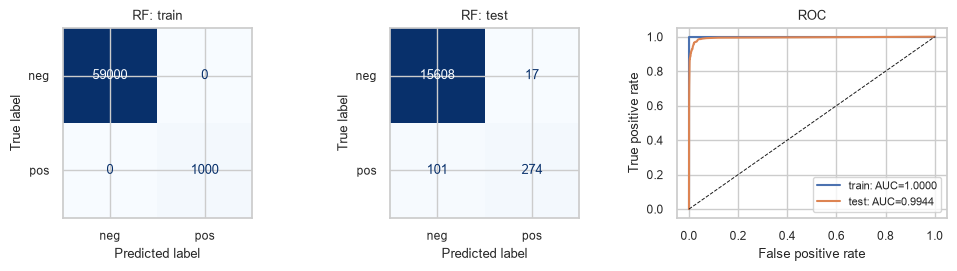

,error,AUC,recall,precision,OOB_error,CV_error
split,,,,,,
train,0.00000,1.00000,1.00000,1.00000,0.0059,NaN
test,0.00738,0.99435,0.73067,0.94158,NaN,NaN


OOB error is 0.5900%; test error is 0.7375%. OOB predictions use trees that did not train on that row. This estimate is conditional on the median preprocessing fitted to the full training set; it is not a separate validation of imputation.

In [7]:
metrics, predictions, fits = [], {}, {}

def evaluate(name, model, train_x, test_x, oob_error=np.nan, cv_error=np.nan):
    fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
    rows = []
    for k, (split, x, y) in enumerate([('train', train_x, y_train), ('test', test_x, y_test)]):
        prob = model.predict_proba(x)[:, 1]
        pred = (prob >= 0.5).astype(int)
        cm = confusion_matrix(y, pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        rows.append({'model': name, 'split': split, 'error': 1-accuracy_score(y, pred),
            'AUC': roc_auc_score(y, prob), 'recall': recall_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'OOB_error': oob_error if split == 'train' else np.nan,
            'CV_error': cv_error if split == 'train' else np.nan})
        ConfusionMatrixDisplay(cm, display_labels=['neg', 'pos']).plot(
            ax=axes[k], colorbar=False, cmap='Blues', values_format='d')
        axes[k].set_title(f'{name}: {split}')
        fpr, tpr, _ = roc_curve(y, prob)
        axes[2].plot(fpr, tpr, label=f'{split}: AUC={roc_auc_score(y, prob):.4f}')
        predictions[f'{name}_{split}'] = prob
    axes[2].plot([0, 1], [0, 1], 'k--', lw=0.7)
    axes[2].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC')
    axes[2].legend(fontsize=8, loc='lower right')
    fig.tight_layout()
    fig.savefig(OUT / f'{name}_evaluation.png', dpi=160)
    plt.show()
    metrics.extend(rows)
    fits[name] = model
    pd.DataFrame(metrics).to_csv(OUT / 'metrics.csv', index=False)
    display(pd.DataFrame(rows).set_index('split')[['error', 'AUC', 'recall', 'precision', 'OOB_error', 'CV_error']])

rf = RandomForestClassifier(n_estimators=200, max_features='sqrt',
    bootstrap=True, oob_score=True, random_state=SEED, n_jobs=JOBS)
rf.fit(Xtr, y_train)
evaluate('RF', rf, Xtr, Xte, oob_error=1-rf.oob_score_)
display(Markdown(f'OOB error is {1-rf.oob_score_:.4%}; test error is '
    f'{metrics[-1]["error"]:.4%}. OOB predictions use trees that did not train on that row. '
    'This estimate is conditional on the median preprocessing fitted to the full training set; '
    'it is not a separate validation of imputation.'))

### (d) Random forest with class balancing
Options include giving the minority class a larger loss weight, drawing
balanced bootstrap samples, or resampling the training data. I use
`class_weight='balanced_subsample'`, which recalculates inverse-frequency
weights in each bootstrap sample. The forest settings are otherwise the same
as in (c), and no test observations are resampled.

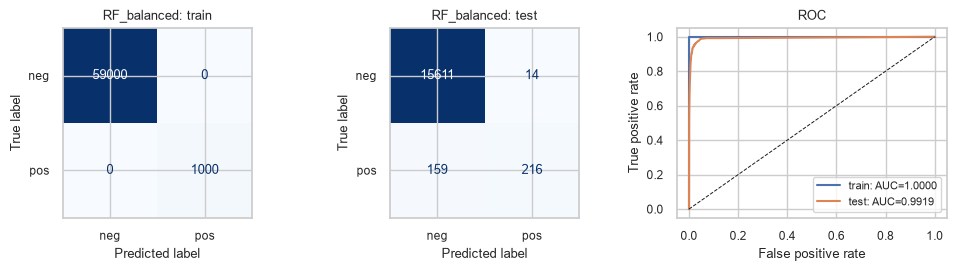

,error,AUC,recall,precision,OOB_error,CV_error
split,,,,,,
train,0.00000,1.0000,1.000,1.00000,0.0077,NaN
test,0.01081,0.9919,0.576,0.93913,NaN,NaN


Test error changes from 0.7375% to 1.0813%, and positive recall from 73.0667% to 57.6000%. False negatives change from 101 to 159; false positives from 17 to 14. The balanced forest has OOB error 0.7700%, compared with test error 1.0813%. Class weighting changes the fitted splits, but does not guarantee better recall at a fixed threshold.

In [8]:
rf_bal = RandomForestClassifier(n_estimators=200, max_features='sqrt',
    bootstrap=True, oob_score=True, class_weight='balanced_subsample',
    random_state=SEED, n_jobs=JOBS)
rf_bal.fit(Xtr, y_train)
evaluate('RF_balanced', rf_bal, Xtr, Xte, oob_error=1-rf_bal.oob_score_)
plain, balanced = metrics[1], metrics[3]
display(Markdown(f'Test error changes from {plain["error"]:.4%} to {balanced["error"]:.4%}, '
    f'and positive recall from {plain["recall"]:.4%} to {balanced["recall"]:.4%}. '
    f'False negatives change from {plain["FN"]} to {balanced["FN"]}; '
    f'false positives from {plain["FP"]} to {balanced["FP"]}. '
    f'The balanced forest has OOB error {1-rf_bal.oob_score_:.4%}, compared with test error {balanced["error"]:.4%}. '
    'Class weighting changes the fitted splits, but does not guarantee better recall at a fixed threshold.'))

### (e) L1-regularized XGBoost without balancing
Piazza @142 confirms that standard XGBoost with L1 regularization is sufficient.
I use `binary:logistic` with `reg_alpha` controlling L1 regularization of leaf
weights. This does not fit a separate logistic regression at each tree node.

I choose alpha from 0, 0.01, 0.1, 1, 10, and 100 using mean error across five
stratified folds. Other settings are fixed: 200 trees, depth 4, learning rate
0.08, and L2 penalty 1. Imputation and scaling are fitted only on each fold's
training rows. The same scaling is used in (e) and (f), since SMOTE uses
distances. The validation folds keep their original class proportions.

The reported CV error is the tuning score for the chosen alpha. It can be
optimistic because alpha is selected using these same folds; the held-out
test error is reported separately. The full-training error is also shown.

XGB: completed fold 1/5; fit rows = 48000


XGB: completed fold 2/5; fit rows = 48000


XGB: completed fold 3/5; fit rows = 48000


XGB: completed fold 4/5; fit rows = 48000


XGB: completed fold 5/5; fit rows = 48000


,CV_error,error_sd,CV_AUC
alpha,,,
0.00,0.00585,0.00049,0.98833
0.01,0.00582,0.00060,0.98932
0.10,0.00580,0.00053,0.98952
1.00,0.00575,0.00071,0.98932
10.00,0.00683,0.00074,0.98917
100.00,0.01102,0.00080,0.98281


Chosen alpha: 1; final fit rows: 60000


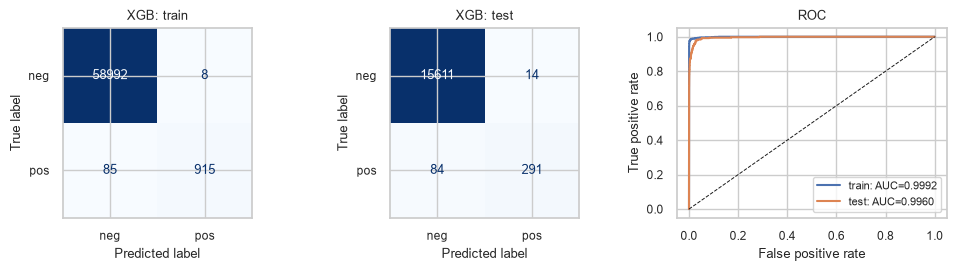

,error,AUC,recall,precision,OOB_error,CV_error
split,,,,,,
train,0.00155,0.99924,0.915,0.99133,NaN,0.00575
test,0.00613,0.99604,0.776,0.95410,NaN,NaN


Mean tuning CV error is 0.5750%; test error is 0.6125%. The training confusion matrix and ROC use the original 60,000 training observations.

In [9]:
alphas = [0, 0.01, 0.1, 1, 10, 100]
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))

def booster(alpha):
    return XGBClassifier(objective='binary:logistic', eval_metric='logloss',
        n_estimators=200, max_depth=4, learning_rate=0.08, reg_alpha=alpha,
        reg_lambda=1, subsample=1, colsample_bytree=1, scale_pos_weight=1,
        tree_method='hist', random_state=SEED, n_jobs=JOBS)

def prepare(train, valid):
    imp = SimpleImputer(strategy='median', keep_empty_features=True)
    scale = StandardScaler()
    a = scale.fit_transform(imp.fit_transform(train)).astype('float32')
    b = scale.transform(imp.transform(valid)).astype('float32')
    return a, b

def tune_xgb(use_smote=False):
    name = 'XGB_SMOTE' if use_smote else 'XGB'
    records = []
    for fold, (tr, va) in enumerate(folds, 1):
        a, b = prepare(X_train.iloc[tr], X_train.iloc[va])
        y = y_train.iloc[tr].to_numpy()
        if use_smote:
            a, y = SMOTE(random_state=SEED, k_neighbors=5).fit_resample(a, y)
            assert np.bincount(y)[0] == np.bincount(y)[1]
        for alpha in alphas:
            model = booster(alpha).fit(a, y)
            prob = model.predict_proba(b)[:, 1]
            records.append({'fold': fold, 'alpha': alpha,
                'error': 1-accuracy_score(y_train.iloc[va], prob >= 0.5),
                'AUC': roc_auc_score(y_train.iloc[va], prob), 'fit_rows': len(y)})
        pd.DataFrame(records).to_csv(OUT / f'{name}_cv_folds.csv', index=False)
        print(f'{name}: completed fold {fold}/5; fit rows = {len(y)}', flush=True)
    scores = pd.DataFrame(records).groupby('alpha').agg(
        CV_error=('error', 'mean'), error_sd=('error', 'std'), CV_AUC=('AUC', 'mean'))
    scores.to_csv(OUT / f'{name}_cv_summary.csv')
    best = float(scores.CV_error.idxmin())
    a, b = prepare(X_train, X_test)
    fit_x, fit_y = a, y_train.to_numpy()
    if use_smote:
        fit_x, fit_y = SMOTE(random_state=SEED, k_neighbors=5).fit_resample(a, fit_y)
        assert fit_x.shape == (118000, 170)
    model = booster(best).fit(fit_x, fit_y)
    display(scores)
    print(f'Chosen alpha: {best:g}; final fit rows: {len(fit_y)}')
    evaluate(name, model, a, b, cv_error=float(scores.loc[best, 'CV_error']))
    display(Markdown(f'Mean tuning CV error is {scores.loc[best, "CV_error"]:.4%}; '
        f'test error is {metrics[-1]["error"]:.4%}. '
        'The training confusion matrix and ROC use the original 60,000 training observations.'))
    return best

alpha_plain = tune_xgb(False)

### (f) XGBoost with SMOTE
SMOTE creates minority examples by interpolating between minority neighbors.
Here it balances the full training data to 59,000 negative and 59,000 positive
rows. Each CV training fold is imputed, scaled, and oversampled separately;
validation and test data are only transformed. Applying SMOTE before splitting
the folds would let related synthetic examples cross the train/validation
boundary and give an overly favorable estimate.

XGB_SMOTE: completed fold 1/5; fit rows = 94400


XGB_SMOTE: completed fold 2/5; fit rows = 94400


XGB_SMOTE: completed fold 3/5; fit rows = 94400


XGB_SMOTE: completed fold 4/5; fit rows = 94400


XGB_SMOTE: completed fold 5/5; fit rows = 94400


,CV_error,error_sd,CV_AUC
alpha,,,
0.00,0.01147,0.00096,0.98579
0.01,0.01147,0.00098,0.98616
0.10,0.01168,0.00125,0.98596
1.00,0.01168,0.00111,0.98582
10.00,0.01257,0.00127,0.98594
100.00,0.02013,0.00092,0.98634


Chosen alpha: 0; final fit rows: 118000


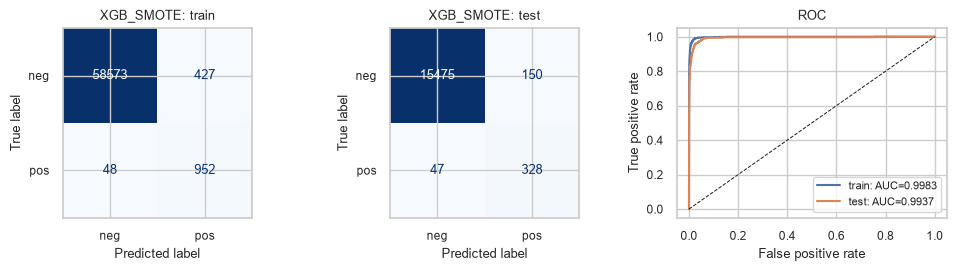

,error,AUC,recall,precision,OOB_error,CV_error
split,,,,,,
train,0.00792,0.99830,0.95200,0.69036,NaN,0.01147
test,0.01231,0.99366,0.87467,0.68619,NaN,NaN


Mean tuning CV error is 1.1467%; test error is 1.2312%. The training confusion matrix and ROC use the original 60,000 training observations.

,error,AUC,recall,precision,FP,FN
model,,,,,,
RF,0.00738,0.99435,0.73067,0.94158,17,101
RF_balanced,0.01081,0.99190,0.57600,0.93913,14,159
XGB,0.00613,0.99604,0.77600,0.95410,14,84
XGB_SMOTE,0.01231,0.99366,0.87467,0.68619,150,47


SMOTE changes test error from 0.6125% to 1.2312%, AUC from 0.99604 to 0.99366, and positive recall from 77.6000% to 87.4667%. False negatives change from 84 to 47, while false positives change from 14 to 150. These results compare the same 0.5 threshold; resampling changes class proportions, so its output probabilities should not automatically be treated as calibrated failure risks.

In [10]:
alpha_smote = tune_xgb(True)
comparison = pd.DataFrame(metrics)
display(comparison[comparison.split == 'test'].set_index('model')[
    ['error', 'AUC', 'recall', 'precision', 'FP', 'FN']])
original, smote = metrics[5], metrics[7]
display(Markdown(f'SMOTE changes test error from {original["error"]:.4%} to {smote["error"]:.4%}, '
    f'AUC from {original["AUC"]:.5f} to {smote["AUC"]:.5f}, '
    f'and positive recall from {original["recall"]:.4%} to {smote["recall"]:.4%}. '
    f'False negatives change from {original["FN"]} to {smote["FN"]}, '
    f'while false positives change from {original["FP"]} to {smote["FP"]}. '
    'These results compare the same 0.5 threshold; resampling changes class proportions, '
    'so its output probabilities should not automatically be treated as calibrated failure risks.'))
np.savez_compressed(OUT / 'predictions.npz', **predictions)
(OUT / 'chosen_parameters.json').write_text(json.dumps(
    {'XGB_alpha': alpha_plain, 'XGB_SMOTE_alpha': alpha_smote, 'seed': SEED}, indent=2));

## 2. ISLR 6.6.3 — Increasing the lasso constraint
The constraint is $\sum_j|\beta_j|\le s$. Increasing $s$ allows more flexible fits.

| Part | Choice | Reason |
|---|---|---|
| (a) Training RSS | iv: decreases | The feasible set expands, so its minimum RSS cannot increase. It levels off once least squares is allowed. |
| (b) Test RSS | ii: decreases, then increases | Initially the fit improves; with less regularization, overfitting can increase test error. |
| (c) Variance | iii: increases | A less constrained fit is more sensitive to the training sample. |
| (d) Squared bias | iv: decreases | Less shrinkage lets the fitted model follow the underlying relationship more closely. |
| (e) Irreducible error | v: constant | Changing the fitted model does not change the noise in the data. |

These are the usual bias–variance trends; a particular test sample need not give a perfect U-shaped curve.

## 3. ISLR 6.6.5 — Identical predictors
Write $x_i=x_{i1}=x_{i2}$ for $i=1,2$. The variables are centered, so the intercept is zero.

**(a)** Ridge minimizes
$$
 (y_1-x_1\beta_1-x_1\beta_2)^2+
 (y_2-x_2\beta_1-x_2\beta_2)^2+
 \lambda(\beta_1^2+\beta_2^2).
$$
**(b)** Let $s=\beta_1+\beta_2$. The RSS depends only on $s$, while
$$\beta_1^2+\beta_2^2=\frac{s^2+(\beta_1-\beta_2)^2}{2}.$$
For fixed $s$ and $\lambda>0$, the penalty is smallest when
$\hat\beta_1=\hat\beta_2=s/2$. Thus ridge splits the coefficient equally.

**(c)** Lasso minimizes
$$
 (y_1-x_1\beta_1-x_1\beta_2)^2+
 (y_2-x_2\beta_1-x_2\beta_2)^2+
 \lambda(|\beta_1|+|\beta_2|).
$$
**(d)** For fixed $s$, the smallest penalty is $\lambda|s|$. Every split with
the same sign attains it. If the optimal sum is $s^*\ne0$, all pairs
$$ (\hat\beta_1,\hat\beta_2)=(t s^*,(1-t)s^*),\qquad 0\le t\le1 $$
give the same objective. For example, $(s^*,0)$ and $(0,s^*)$ are both solutions.
More explicitly, for $A=\sum_i x_i^2>0$ and $C=\sum_i x_i y_i$,
$$s^*=\frac{\operatorname{sign}(C)(|C|-\lambda/2)_+}{A}.$$
There is one exception to the non-uniqueness claim: if shrinkage makes $s^*=0$
and $\lambda>0$, the solution is uniquely $(0,0)$.

## 4. ISLR 8.4.5 — Combining ten trees
Six of the ten trees assign Red probability above 0.5, so **majority vote predicts Red**.
The average probability is
$$\bar p=\frac{0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75}{10}=0.45.$$
Since $0.45<0.5$, **averaging probabilities predicts Green**.

## 5. ISLR 9.7.3 — Maximal margin classifier
**(a)** The left plot below shows the seven observations.

**(b)** The optimal separating hyperplane is $X_2=X_1-\tfrac12$.
The closest Red points lie on $X_2=X_1$, and the closest Blue points lie on
$X_2=X_1-1$. The boundary lies halfway between these parallel lines.

**(c)** Predict Red if $\tfrac12-X_1+X_2>0$, and Blue if it is negative.
Thus $(\beta_0,\beta_1,\beta_2)=(\tfrac12,-1,1)$. A point exactly on the
boundary can be assigned either class by a fixed tie rule.

**(d)** The margin from the boundary to either class is
$M=\frac{1/2}{\sqrt{(-1)^2+1^2}}=\frac{1}{2\sqrt2}$.
The total width between the two dashed margin lines is $1/\sqrt2$.

**(e)** Support vectors are observations **2, 3, 5, and 6**:
$(2,2),(4,4),(2,1),(4,3)$. They are circled in the plot.
The two class convex hulls contain parallel edges at distance $1/\sqrt2$,
so no separating line can give a larger minimum distance than half of this.

**(f)** Observation 7, $(4,1)$, is well outside the margin and is not a support
vector. A sufficiently small move leaves the supporting edges unchanged.

**(g)** One separating line that is not optimal is $X_2=X_1-\tfrac14$.
Its minimum distance to a point is $1/(4\sqrt2)$, smaller than the optimal margin.

**(h)** Add a Blue point at $(2,3)$. It lies inside the Red triangle with
vertices $(1,4),(2,2),(3,4)$, since it is their weighted average with weights
$1/4,1/2,1/4$. A line cannot separate it from all Red points.

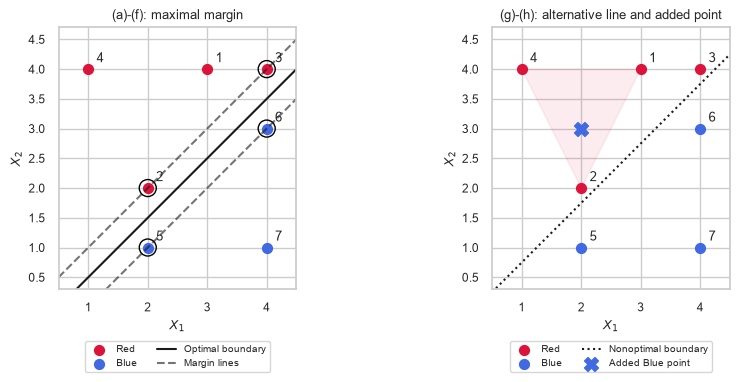

In [11]:
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
labels = np.array([1, 1, 1, 1, -1, -1, -1])
support = np.array([1, 2, 4, 5])
signed = labels * (0.5 - points[:, 0] + points[:, 1]) / np.sqrt(2)
assert np.allclose(signed[support], 1/(2*np.sqrt(2)))
assert (labels * (0.25 - points[:, 0] + points[:, 1]) > 0).all()
assert np.allclose(.25*points[3] + .5*points[1] + .25*points[0], [2, 3])
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
xx = np.linspace(.5, 4.5, 100)
for ax in axes:
    ax.scatter(*points[:4].T, color='crimson', label='Red', s=50)
    ax.scatter(*points[4:].T, color='royalblue', label='Blue', s=50)
    for i, (x, y) in enumerate(points, 1):
        ax.annotate(str(i), (x, y), xytext=(6, 5), textcoords='offset points')
    ax.set(xlim=(.5, 4.5), ylim=(.3, 4.7), xlabel='$X_1$', ylabel='$X_2$')
    ax.set_aspect('equal')
axes[0].plot(xx, xx-.5, 'k-', label='Optimal boundary')
axes[0].plot(xx, xx, 'k--', alpha=.6)
axes[0].plot(xx, xx-1, 'k--', alpha=.6, label='Margin lines')
axes[0].scatter(*points[support].T, s=150, facecolors='none', edgecolors='black')
axes[0].set_title('(a)-(f): maximal margin')
axes[1].plot(xx, xx-.25, 'k:', label='Nonoptimal boundary')
axes[1].fill([1, 2, 3], [4, 2, 4], color='crimson', alpha=.08)
axes[1].scatter(2, 3, marker='X', color='royalblue', s=100, label='Added Blue point')
axes[1].set_title('(g)-(h): alternative line and added point')
for ax in axes:
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.18), ncol=2, fontsize=7)
fig.tight_layout()
fig.savefig(OUT / 'maximal_margin.png', dpi=180, bbox_inches='tight')
plt.show()

### References
- [Scikit-learn: missing-value imputation](https://scikit-learn.org/stable/modules/impute.html).
- [Scikit-learn: RandomForestClassifier and class weights](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).
- [XGBoost parameters: reg_alpha](https://xgboost.readthedocs.io/en/stable/parameter.html).
- [Imbalanced-learn: avoiding leakage during resampling](https://imbalanced-learn.org/stable/common_pitfalls.html).
- [ISLR, first edition](https://www.statlearning.com/s/ISLR-Seventh-Printing.pdf), Chapter 6 exercises 3 and 5 (pp. 260–261), Chapter 8 exercise 5, and Chapter 9 exercise 3. Chapter 6 is numbered 6.8 in this printing; the headings above keep the assignment's numbering.
- [Piazza @142](https://piazza.com/class/mt7h6ldc1j86hm/post/142): standard XGBoost with L1 regularization is sufficient for part (e).